In [95]:
import pandas as pd
import kagglehub

path = kagglehub.dataset_download("nehalbirla/vehicle-dataset-from-cardekho")
df = pd.read_csv(f"{path}/Car details v3.csv")

In [96]:
import numpy as np
df = df.drop_duplicates()

df['car_age'] = 2026 - df['year']

df = df[df['mileage'].str.split().str[-1] == "kmpl"]
df['mileage'] = df['mileage'].str.split().str[0].astype(float)
df['engine'] = df['engine'].str.split().str[0].astype(float)
df['max_power'] = df['max_power'].str.split().str[0].astype(float)
df['mileage'] = df['mileage'].replace(0, np.nan)

df = df.drop(columns=["name", "year", "torque"]).reset_index().drop(columns=["index"])

In [97]:
df.head()

,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,car_age
0,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,12
1,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,12
2,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,20
3,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,16
4,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,19


In [98]:
df["max_power"].describe()

count    6631.000000
mean       88.118980
std        31.748478
min        34.200000
25%        68.000000
50%        81.860000
75%       100.000000
max       400.000000
Name: max_power, dtype: float64

In [99]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6631 entries, 0 to 6630
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   selling_price  6631 non-null   int64  
 1   km_driven      6631 non-null   int64  
 2   fuel           6631 non-null   str    
 3   seller_type    6631 non-null   str    
 4   transmission   6631 non-null   str    
 5   owner          6631 non-null   str    
 6   mileage        6616 non-null   float64
 7   engine         6631 non-null   float64
 8   max_power      6631 non-null   float64
 9   seats          6631 non-null   float64
 10  car_age        6631 non-null   int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 570.0 KB


In [100]:
df.describe()

,selling_price,km_driven,mileage,engine,max_power,seats,car_age
count,6.631000e+03,6.631000e+03,6616.000000,6631.000000,6631.000000,6631.000000,6631.000000
mean,5.296566e+05,7.336993e+04,19.478599,1435.693259,88.118980,5.440054,12.385462
std,5.260015e+05,5.882501e+04,3.907658,494.553445,31.748478,0.988312,3.900434
min,2.999900e+04,1.000000e+03,9.000000,624.000000,34.200000,2.000000,6.000000
25%,2.500000e+05,3.715600e+04,16.800000,1197.000000,68.000000,5.000000,9.000000
50%,4.250000e+05,6.800000e+04,19.400000,1248.000000,81.860000,5.000000,12.000000
75%,6.500000e+05,1.000000e+05,22.480000,1498.000000,100.000000,5.000000,15.000000
max,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,14.000000,32.000000


array([[<Axes: title={'center': 'selling_price'}>,
        <Axes: title={'center': 'km_driven'}>,
        <Axes: title={'center': 'mileage'}>],
       [<Axes: title={'center': 'engine'}>,
        <Axes: title={'center': 'max_power'}>,
        <Axes: title={'center': 'seats'}>],
       [<Axes: title={'center': 'car_age'}>, <Axes: >, <Axes: >]],
      dtype=object)

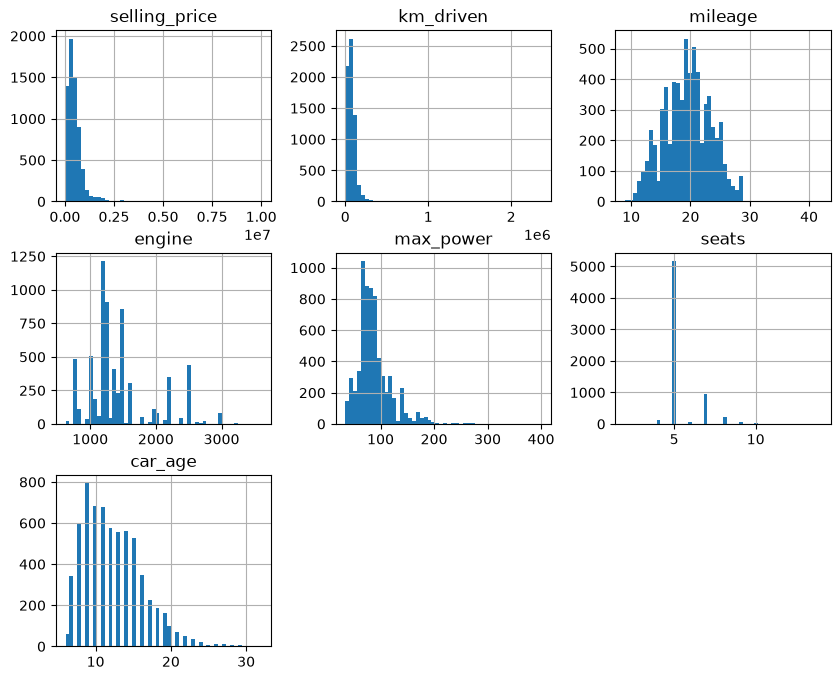

In [101]:
df.hist(bins=(50), figsize=(10, 8))

In [102]:
df.corr(numeric_only=True)["selling_price"].sort_values(ascending=False)

selling_price    1.000000
max_power        0.691988
engine           0.440669
seats            0.156168
mileage         -0.108095
km_driven       -0.161139
car_age         -0.427998
Name: selling_price, dtype: float64

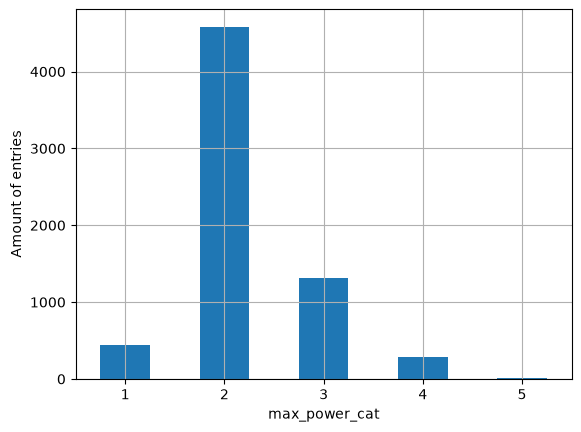

In [103]:
import matplotlib.pyplot as plt

df["max_power_cat"] = pd.cut(df["max_power"], bins=[0.0, 50.0, 100.0, 150.0, 250.0, np.inf], labels=[1, 2, 3, 4, 5])

cat_counts = df["max_power_cat"].value_counts().sort_index()
cat_counts.plot.bar(rot=0, grid=True)
plt.xlabel("max_power_cat")
plt.ylabel("Amount of entries")
plt.show()

In [104]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(df, test_size=0.2, stratify=df["max_power_cat"], random_state=42)
train_set = train_set.drop("max_power_cat", axis=1)
test_set = test_set.drop("max_power_cat", axis=1)

X_train, y_train = train_set.drop("selling_price", axis=1), train_set["selling_price"]

In [105]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

owner_categories = ["Test Drive Car", "First Owner", "Second Owner", "Third Owner", "Fourth & Above Owner"]

num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

cat_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

owner_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OrdinalEncoder(categories=[owner_categories])),
    ("scale", StandardScaler()),
])

num_attributes = ["max_power", "engine", "seats", "mileage", "km_driven", "car_age"]
cat_attributes = ["fuel", "seller_type", "transmission"]

preprocessing = ColumnTransformer([
    ("num", num_pipeline, num_attributes),
    ("cat", cat_pipeline, cat_attributes),
    ("owner", owner_pipeline, ["owner"]),
])

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()